Mount drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Get the dataset Folder from the drive

In [2]:
import glob

folder = "/content/drive/MyDrive/ML/Projectcyberdetection/dataset"
files = sorted(glob.glob(folder + "/*.csv"))
for f in files:
    print(f)
print(len(files))

/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f1.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f2.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f3.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f4.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f5.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f6.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f7.csv
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f8.csv
8


First Check the File 1 data Shape

In [3]:
import pandas as pd

df = pd.read_csv(files[0], low_memory=False)
df.columns = df.columns.str.strip()   # column names ke extra spaces hataein

print(df.shape)
print(df["Label"].value_counts())

(286467, 85)
Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64


All 8 files load and reduce there size Because  of RAM

In [5]:
dfs = []
for f in files:
    temp = pd.read_csv(f, low_memory=False, encoding="latin-1")
    temp.columns = temp.columns.str.strip()

    # float64 ko float32 banao, RAM aadhi ho jati hai
    float_cols = temp.select_dtypes("float64").columns
    temp[float_cols] = temp[float_cols].astype("float32")

    dfs.append(temp)
    print(f, temp.shape)

data = pd.concat(dfs, ignore_index=True)
del dfs        # RAM free karein
print("Total:", data.shape)

/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f1.csv (286467, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f2.csv (225745, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f3.csv (191033, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f4.csv (529918, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f5.csv (288602, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f6.csv (458968, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f7.csv (445909, 85)
/content/drive/MyDrive/ML/Projectcyberdetection/dataset/f8.csv (692703, 85)
Total: (3119345, 85)


Checks Data imbalance, BENIGN and Attacks

In [6]:
print(data["Label"].value_counts())

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack  Brute Force         1507
Web Attack  XSS                  652
Infiltration                       36
Web Attack  Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


Plot to check the data class imbalance

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


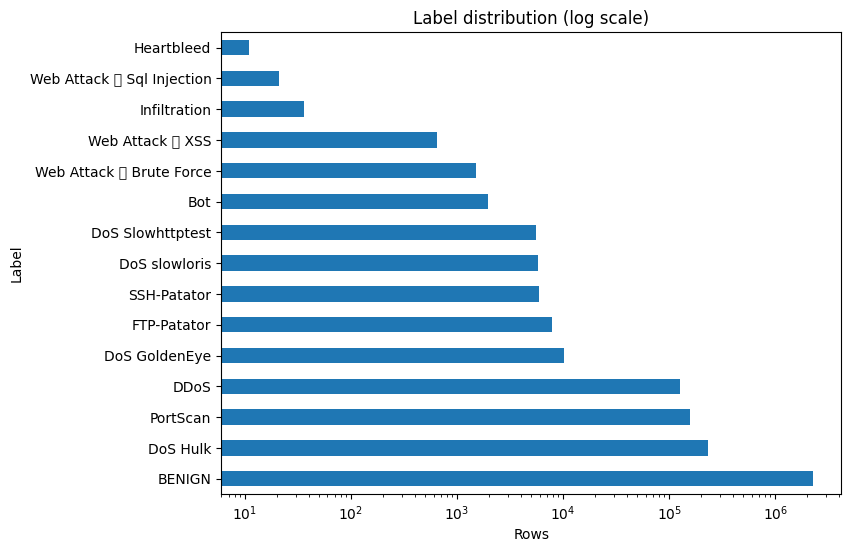

In [7]:
import matplotlib.pyplot as plt

data["Label"].value_counts().plot(kind="barh", figsize=(8,6), logx=True)
plt.title("Label distribution (log scale)")
plt.xlabel("Rows")
plt.show()

Replacing Empty spaces with NaN

In [8]:
import numpy as np

print("starting shape:", data.shape)

data.replace([np.inf, -np.inf], np.nan, inplace=True)

print("NaN rows:", data.isna().any(axis=1).sum())

starting shape: (3119345, 85)
NaN rows: 291469


Removing the NaN Rows

In [9]:
data.dropna(inplace=True)
print("After shape:", data.shape)

Cleaning ke baad shape: (2827876, 85)


Checks Labels data after removing these columns

In [10]:
print(data["Label"].value_counts())

Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack  Brute Force         1507
Web Attack  XSS                  652
Infiltration                       36
Web Attack  Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


Removing Unnessary Columns

In [11]:
id_cols = ["Flow ID", "Src IP", "Dst IP", "Src Port", "Source IP", "Destination IP", "Source Port", "Timestamp"]
to_drop = [c for c in id_cols if c in data.columns]
print("drop columns:", to_drop)

data.drop(columns=to_drop, inplace=True)
print("Shape:", data.shape)

drop columns: ['Flow ID', 'Source IP', 'Destination IP', 'Source Port', 'Timestamp']
Shape: (2827876, 80)


finding Duplicates

In [12]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 329717


Drop Dublicates Rows

In [13]:
data.drop_duplicates(inplace=True)
print("Shape:", data.shape)

Shape: (2498159, 80)


Those columns that only show same values so these column need to remove they cannot train the dataset.In this identify the Columns

In [15]:
const_cols = [c for c in data.columns if data[c].nunique() == 1]
print("Constant columns:", const_cols)

Constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


Drop these unrelated columns from the dataset

In [16]:
data.drop(columns=const_cols, inplace=True)
print("Shape:", data.shape)

Shape: (2498159, 72)


Encoding of text to number True and false

In [17]:
data["Label"] = (data["Label"] != "BENIGN").astype(int)
print(data["Label"].value_counts())

Label
0    2072418
1     425741
Name: count, dtype: int64


show types

In [18]:
print(data.dtypes.value_counts())

float64    47
float32    24
int64       1
Name: count, dtype: int64


In [19]:
feature_cols = data.columns.drop("Label")
data[feature_cols] = data[feature_cols].astype("float32")
print(data.dtypes.value_counts())

float32    71
int64       1
Name: count, dtype: int64


In [20]:
data.to_parquet("/content/drive/MyDrive/ML/Projectcyberdetection/clean_data.parquet")